In [32]:
import pandas as pd
import re
import json
import ast
from os import fdopen, remove
from tempfile import mkstemp
from shutil import move, copymode
from pprint import pprint 
from io import StringIO
import os
import string
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

import spacy
nlp = spacy.load('de_core_news_lg') # oder de_core_news_sm


def flatten(xss):
    return [x for xs in xss for x in xs]

### Daten veranschaulichen:
- Häufigkeit der KI Terme
- Häufigste Wörter
- TF-IDF Wörter Veranschaulichen
- length of sentences / number of clauses
- number / type of verbs
- number / type of adjektives

In [16]:
plots_dir = "plots/"
try:
    os.mkdir(plots_dir)
    print(f"Directory '{plots_dir}' created successfully.")
except FileExistsError:
    print(f"Directory '{plots_dir}' already exists.")

Directory 'plots/' already exists.


In [17]:
docs_ki = pd.read_json(StringIO(open('generated_data/KI_sentences_tfidf.json').read()), orient="index")

ki_docs = docs_ki[docs_ki['sentences'].isna() == False].reset_index()
non_ki_docs = docs_ki[docs_ki['sentences'].isna() == True].reset_index()

print(f"Number of KI docs: {len(ki_docs)}")
print(f"Number of other docs: {len(non_ki_docs)}")
non_ki_docs.head()

Number of KI docs: 0
Number of other docs: 152134


,index,sentences,top_words
0,6036703.txt,NaN,"['unterstützen', 'zwangshaft söder', 'genüssli..."
1,0224025.txt,NaN,"['zivilisten dramatischen', 'nkunda erschütter..."
2,5903496.txt,NaN,"['kommunist laufe', 'radikalisieren', 'kommuni..."
3,1184664.txt,NaN,"['andré', 'andré kunz', 'kunz', 'ishikawa prof..."
4,806049.txt,NaN,"['patienten fördern', 'patienten', 'gesundheit..."


In [18]:
docs_ai = pd.read_json(StringIO(open('generated_data/AI_sentences_tfidf.json').read()), orient="index")

ai_docs = docs_ai[docs_ai['sentences'].isna() == False].reset_index()
non_ai_docs = docs_ai[docs_ai['sentences'].isna() == True].reset_index()

print(f"Number of AI docs: {len(ai_docs)}")
print(f"Number of other docs: {len(non_ai_docs)}")
docs_ai.head()

Number of AI docs: 0
Number of other docs: 574


,sentences,top_words
5315432.txt,NaN,"['scooter 25', 'scooter', 'pushes scooter', 'p..."
5124643.txt,NaN,"['unarmed civilians', 'government forces', 'ba..."
5094180.txt,NaN,"['weiwei does', 'weiwei', 'shortcoming', 'nomi..."
851887.txt,NaN,"['philipp palm', 'philipp', 'palm crisis', 'pa..."
5455271.txt,NaN,"['world 2000', 'world', 'ki', '2000 ki', '2000']"


In [19]:
# filtered Ki sentences with regex
docs_sents = pd.read_csv(StringIO(open('generated_data/KI_sentences_translated.csv').read()))
docs_full = pd.read_csv(StringIO(open('generated_data/KI_sentences_full_translated.csv').read()))

with open("generated_data/Leipzig_KI_sentences_all.json", "r") as f:
    docs_leipzig = json.load(f)

print(f"Number of docs_full: {len(docs_full)}")
print(f"Number of docs_sents: {len(docs_sents)}")
docs_sents.head()

Number of docs_full: 150
Number of docs_sents: 1490


,id,text,translation
0,5315432.txt,der elek­tro­mo­tor pusht den rol­ler auf bis ...,the electric motor pushes the scooter up to 25...
1,5124643.txt,ungeneralsekretär ban ki moon bezeichnete die ...,secretary-general ban ki moon calls the killin...
2,5094180.txt,gegen dieses manko hilft auch die nominierung ...,"even the nomination of the chinese ""architect""..."
3,851887.txt,taz herr palm man liest von gewalt an ihrer sc...,taz mr palm you read about violence at your sc...
4,851887.txt,philipp palm es ist nicht so dass wir in einer...,philipp palm it is not that we are in a seriou...


In [33]:
# Häufigste Wörter insgesamt
def top_words(df_col, k):
    top_k = df_col.value_counts().head(k)
    print(f"\n{k} most frequent words:\n", top_k)
    return top_k

# Häufigste Wörter pro jahr 
def top_words_year(df):
    try:
        with open('corpus_texts/taz24_metadata.json', 'r', encoding='utf-8') as f:
            meta = json.load(f)
    except FileNotFoundError:
        raise FileNotFoundError("metadata file not found")

    df_res = pd.DataFrame(df).copy()
    year_col = []
    # Map ids in dataframe to years using metadata; fall back to extracting year from id if present
    for id_df in df["id"]:
        id_str = re.sub(r'\.\w+$', '', id_df).replace('_full', '')  # remove file extension and underscores
        if id_str not in meta:
            print(f"Warning: id {id_df, id_str} not found in metadata")
        else:
            meta_year = meta[id_str].get("published_on")
            year = re.match(r'(\d{4})', meta_year).group(1)
            if year is None:
                print(f"Warning: published_on missing for id {id_df, id_str} in metadata")
                year_col.append("0000")
            else:
                year_col.append(year)
    df_res['year'] = year_col
    df_res.to_csv("generated_data/KI_sentences_years.csv", index=False)
    
    return df_res


def get_POS(token_list):
    return [token.pos_ for token in token_list]

# helper to obtain tokens from an element
def tokens_from_item(item, nlp):
    # spaCy Token lists / Docs / Spans 
    if hasattr(item, "pos_") or (hasattr(item, "__iter__") and not isinstance(item, str) and len(item) and hasattr(item[0], "pos_")):
        # item is a Token, Doc, Span, or list of Tokens
        return list(item)
    return list(nlp(str(item)))

# Count top words by POS tag (supports token lists, spaCy Docs/Spans, or raw text)
def get_top_POS(df_col, pos, k):
    # detect whether we need to load a model (when any element is a string)
    try:
        # df_col can be a pandas Series
        iterable = df_col
        if hasattr(df_col, "dropna"):
            iterable = df_col.dropna().values
    except Exception:
        iterable = df_col

    counts = Counter()
    for item in iterable:
        tokens = _tokens_from_item(item, nlp)
        for token in tokens:
            # ensure token has pos_ and is alphabetic
            if getattr(token, "pos_", None) == pos and getattr(token, "is_alpha", False):
                lemma = getattr(token, "lemma_", token.text).lower()
                counts[lemma] += 1

    top_k = pd.Series(dict(counts.most_common(k)))
    print(f"\n{k} most frequent {pos}:\n", top_k)
    # save to file
    top_k.to_csv(f'generated_data/{pos}_{df_col}')
    return top_k

#### TFIDF of KI_sentences filtered with regex

In [21]:
# compare KI_sentences and KI_sentences_full ids
ids_full = [x.replace("_full", "") for x in docs_full["id"].tolist()]
all_ids = docs_sents["id"].tolist() + ids_full
set_all_ids = set(all_ids)
set_all_og_ids = set(docs_sents["id"].tolist() + docs_full["id"].tolist())
non_repeated_ids = [x for x in set_all_ids if x not in ids_full] + [x for x in ids_full if x not in set_all_ids]
print(f"Number of ids: {len(all_ids)}, len unique ids: {len(set_all_ids)}, len non-repeated ids: {len(non_repeated_ids)}")
print("Non-repeated ids:", str(non_repeated_ids))
print("all original ids:", str(set_all_og_ids))

# separate tfidf of ai-sentences and others


# combine

# calc tfidf on result

# visualize, ideally against other tfidf(s)


Number of ids: 1640, len unique ids: 578, len non-repeated ids: 428
Non-repeated ids: ['1249412.txt', '1738195.txt', '0243231.txt', '0242523.txt', '5777783.txt', '5727292.txt', '5093213.txt', '5092828.txt', '851039.txt', '788192.txt', '5573832.txt', '5050358.txt', '3197013.txt', '5896979.txt', '5024842.txt', '1459696.txt', '5123854.txt', '855097.txt', '1247624.txt', '1902527.txt', '5050367.txt', '5826998.txt', '1363630.txt', '5573351.txt', '0405242.txt', '5320721.txt', '496673.txt', '5069742.txt', '5905841.txt', '5322497.txt', '5192489.txt', '1185257.txt', '5050210.txt', '590719.txt', '1398945.txt', '5050726.txt', '5488023.txt', '0311176.txt', '5069465.txt', '5050337.txt', '477824.txt', '5572208.txt', '5572103.txt', '0405973.txt', '1401971.txt', '5453872.txt', '499512.txt', '5777675.txt', '5485956.txt', '1459861.txt', '0403906.txt', '5148089.txt', '1923030.txt', '5905596.txt', '0316205.txt', '5050457.txt', '853296.txt', '0308485.txt', '5320774.txt', '5094450.txt', '0319763.txt', '51845

#### KI_sentence stats

In [22]:
# number of sentences per year — compute and plot
sents_by_year = top_words_year(docs_sents)

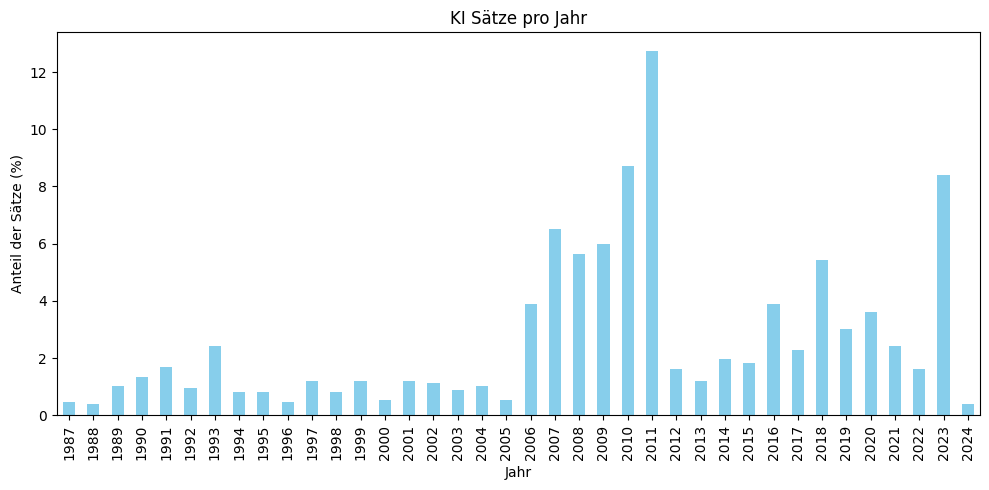

<Figure size 640x480 with 0 Axes>

In [23]:
# exclude unknown years ('0000') and aggregate counts
sents_years = pd.Series(sents_by_year['year'])
sents_years = sents_years[sents_years != '0000']
sents_years = sents_years.value_counts().sort_index()
# calc percentaes
sents_by_year_percent = (sents_years / sents_years.sum()) * 100
sents_by_year_percent = sents_by_year_percent.round(2)
# save percentages
pd.DataFrame({'year': sents_years, 'percentage': sents_by_year_percent}).to_csv('generated_data/KI_sentences_years_percentage.csv',index= False)
# plot
plt.figure(figsize=(10,5))
sents_by_year_percent.plot(kind='bar', color='skyblue')
plt.title('KI Sätze pro Jahr')
plt.xlabel('Jahr')
plt.ylabel('Anteil der Sätze (%)')
plt.tight_layout()
plt.show()
plt.savefig(os.path.join(plots_dir, 'KI_sentences_per_year.png'))

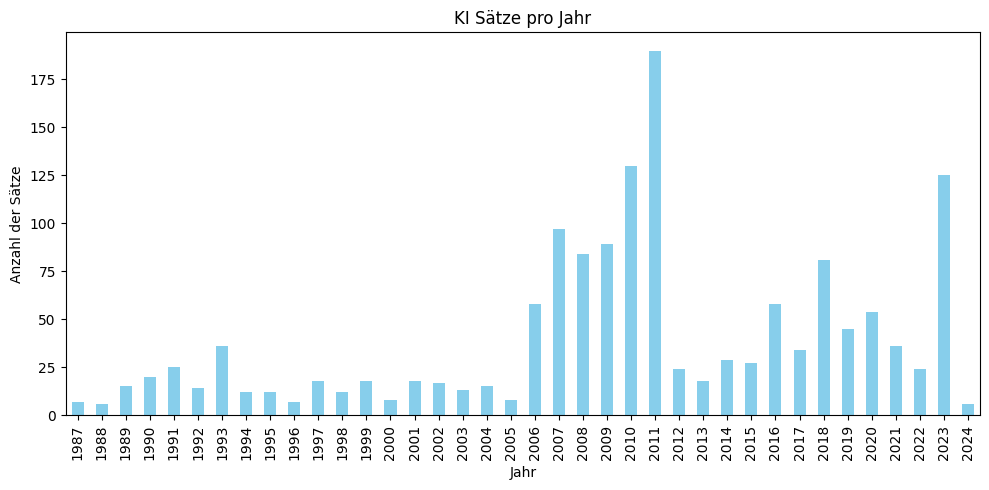

<Figure size 640x480 with 0 Axes>

In [24]:
# exclude unknown years ('0000') and aggregate counts
sents_years = pd.Series(sents_by_year['year'])
sents_years = sents_years[sents_years != '0000']
sents_by_year_count = sents_years.value_counts().sort_index()

# plot
plt.figure(figsize=(10,5))
sents_by_year_count.plot(kind='bar',color='skyblue')
plt.title('KI Sätze pro Jahr')
plt.xlabel('Jahr')
plt.ylabel('Anzahl der Sätze')
plt.tight_layout()
plt.show()
plt.savefig(os.path.join(plots_dir, 'KI_sentences_percent_per_year.png'))

In [25]:
# docs_leipzig is a dict loaded from JSON
# Extract IDs and map to years using metadata, conertd to df
rows = []
for d_id, sent in docs_leipzig.items():
    for i in docs_leipzig[d_id]:
    # Add one row per item
        rows.append({
            "id": docs_leipzig[d_id],
            "year": re.sub(r'\_\w+$', '', d_id) ,
            "text": docs_leipzig[d_id][i],
        })
leipzig_df = pd.DataFrame(rows)
leipzig_df.to_csv('generated_data/Leipzig_sentences_years.csv', index=False)

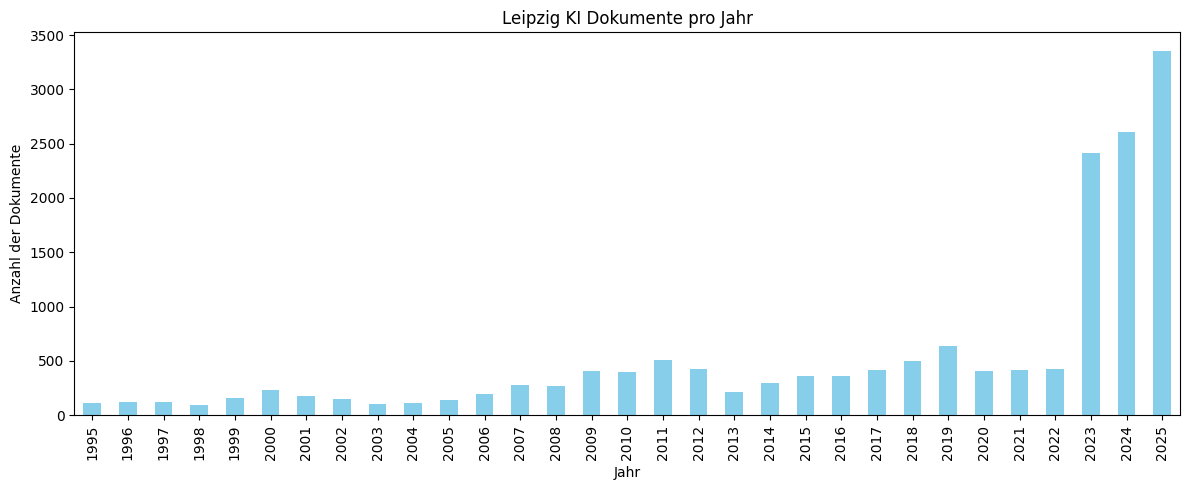

Total Leipzig docs with valid year: 16425
Year range: 1995 - 2025


<Figure size 640x480 with 0 Axes>

In [26]:
# Plot Leipzig docs with id mapped to year
# Count docs per year
leipzig_by_year = leipzig_df['year'].value_counts().sort_index()

# Plot
plt.figure(figsize=(12, 5))
leipzig_by_year.plot(kind='bar',color='skyblue')
plt.title('Leipzig KI Dokumente pro Jahr')
plt.xlabel('Jahr')
plt.ylabel('Anzahl der Dokumente')
plt.tight_layout()
plt.show()
plt.savefig(os.path.join(plots_dir, 'Leipzig_docs_per_year.png'))

print(f"Total Leipzig docs with valid year: {len(leipzig_df)}")
print(f"Year range: {leipzig_df['year'].min()} - {leipzig_df['year'].max()}")

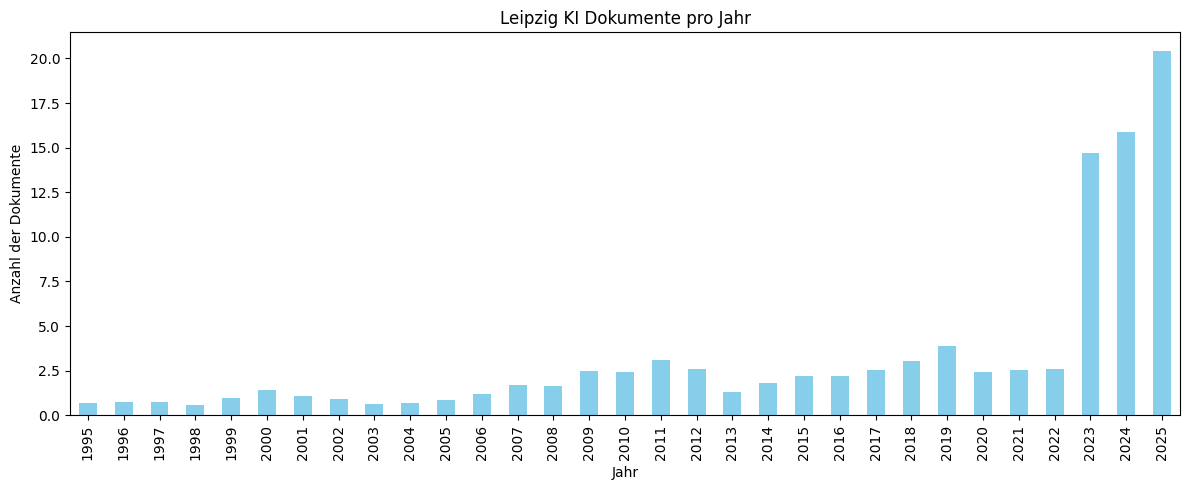

Total Leipzig docs with valid year: 16425
Year range: 1995 - 2025


<Figure size 640x480 with 0 Axes>

In [27]:
# percentage of Leipzig corpora KI sentences per year
# Plot Leipzig docs with id mapped to year in %
leipzig_by_year = leipzig_df['year'].value_counts().sort_index()
# calc percentaes
leipzig_by_year_percent = (leipzig_by_year / leipzig_by_year.sum()) * 100
leipzig_by_year_percent = leipzig_by_year_percent.round(2)
# save percentages
pd.DataFrame({'year': leipzig_by_year, 'percentage': leipzig_by_year_percent}).to_csv('generated_data/Leipzig_sentences_years_percentage.csv',index= False)

# Plot
plt.figure(figsize=(12, 5))
leipzig_by_year_percent.plot(kind='bar', color='skyblue')
plt.title('Leipzig KI Dokumente pro Jahr')
plt.xlabel('Jahr')
plt.ylabel('Anzahl der Dokumente')
plt.tight_layout()
plt.show()
plt.savefig(os.path.join(plots_dir, 'Leipzig_docs_percentage_year.png'))

print(f"Total Leipzig docs with valid year: {len(leipzig_df)}")
print(f"Year range: {leipzig_df['year'].min()} - {leipzig_df['year'].max()}")

In [28]:
# Häufigkeit der einzelnen KI Terme für beide datensätze
# convert leipzig_docs to dataframe as docs_sents with ids, sentences and years
all_sents_df = pd.concat([pd.read_csv("generated_data/KI_sentences_years.csv"), pd.read_csv("generated_data/Leipzig_sentences_years.csv")], ignore_index=True)
pprint(all_sents_df.head())

# average length of sentences
all_sents_df['sentence_length'] = all_sents_df['text'].apply(lambda x: len(x.split()))
avg_length = all_sents_df['sentence_length'].mean()
print("------------------------------------------------------------")
print(f"Average sentence length: {avg_length:.2f} words")


            id                                               text  \
0  5315432.txt  der elek­tro­mo­tor pusht den rol­ler auf bis ...   
1  5124643.txt  ungeneralsekretär ban ki moon bezeichnete die ...   
2  5094180.txt  gegen dieses manko hilft auch die nominierung ...   
3   851887.txt  taz herr palm man liest von gewalt an ihrer sc...   
4   851887.txt  philipp palm es ist nicht so dass wir in einer...   

                                         translation  year  
0  the electric motor pushes the scooter up to 25...  2016  
1  secretary-general ban ki moon calls the killin...  2011  
2  even the nomination of the chinese "architect"...  2012  
3  taz mr palm you read about violence at your sc...  2008  
4  philipp palm it is not that we are in a seriou...  2008  
------------------------------------------------------------
Average sentence length: 18.87 words


In [29]:
# number and type of verbs using tokens_from_item()
def count_POS(df_col, nlp, pos_tag): # Verb, ADJ, etc.
    tag_count = 0
    tag_types = Counter()
    for text in df_col:
        tokens = tokens_from_item(text, nlp)
        for token in tokens:
            if token.pos_ == pos_tag:
                tag_count += 1
                tag_types[token.lemma_] += 1
    print(f"Total {pos_tag}s: {tag_count}")
    print(f"{pos_tag} types:")
    for tag, count in tag_types.most_common():
        print(f"  {tag}: {count}")
    # plot top 20 types
    top_tags = tag_types.most_common(20)
    tags, counts = zip(*top_tags)
    plt.figure(figsize=(10,5))
    plt.bar(tags, counts)
    plt.title(f'Top {pos_tag} types')
    plt.xlabel(f'{pos_tag} lemma')
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    plt.savefig(os.path.join(plots_dir, f'top_{pos_tag}_types.png')) 



Total VERBs: 30298
VERB types:
  sagen: 617
  geben: 554
  machen: 504
  nutzen: 467
  kommen: 430
  gehen: 407
  zeigen: 344
  sehen: 336
  stehen: 322
  setzen: 303
  entwickeln: 280
  lassen: 277
  stellen: 274
  bringen: 259
  einsetzen: 242
  bieten: 232
  erklären: 226
  helfen: 209
  schreiben: 209
  arbeiten: 204
  finden: 195
  sprechen: 187
  spielen: 178
  haben: 178
  bleiben: 175
  lernen: 162
  fordern: 162
  führen: 157
  erstellen: 157
  halten: 154
  erkennen: 150
  lässt: 147
  unterstützen: 147
  liegen: 140
  heißen: 134
  verändern: 134
  übernehmen: 130
  verwenden: 130
  schaffen: 124
  nehmen: 122
  erhalten: 120
  wissen: 118
  nennen: 117
  ermöglichen: 116
  gelten: 111
  verbessern: 111
  trainieren: 109
  treffen: 108
  berichten: 106
  bekommen: 105
  ersetzen: 100
  verstehen: 99
  gehören: 98
  laufen: 97
  liefern: 95
  brauchen: 93
  sorgen: 92
  vorstellen: 87
  tun: 85
  integrieren: 82
  fahren: 81
  ziehen: 80
  veröffentlichen: 79
  warnen: 78
  v

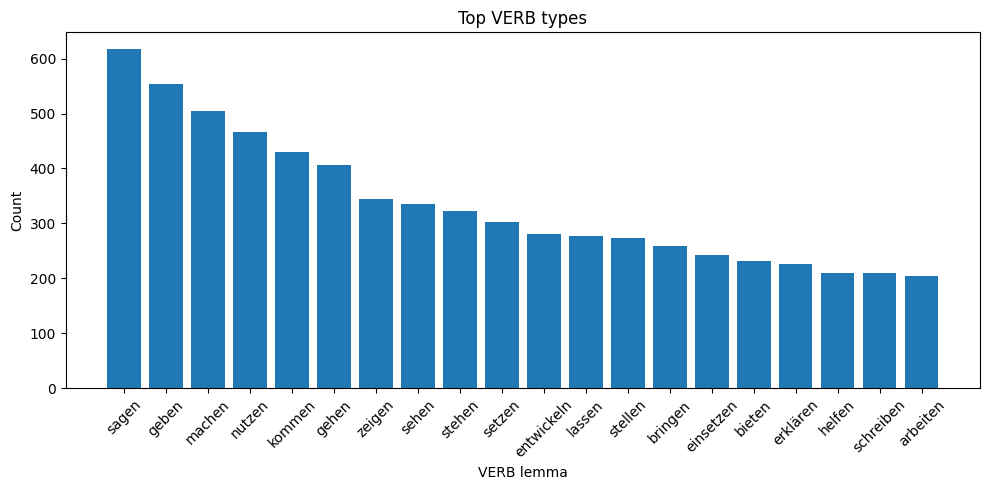

<Figure size 640x480 with 0 Axes>

In [34]:
# count verbs in all sentences
count_POS(all_sents_df['text'], nlp, 'VERB')

Total ADJs: 22854
ADJ types:
  künstlich: 3245
  neu: 971
  groß: 505
  erster: 329
  anderer: 301
  deutsch: 267
  eigen: 257
  weit: 224
  gut: 224
  chinesisch: 196
  digital: 176
  vergangen: 157
  menschlich: 154
  hoch: 152
  wichtig: 136
  letzter: 128
  generativ: 128
  nächster: 123
  aktuell: 121
  Unogeneralsekretär: 116
  international: 114
  jung: 114
  Audi: 113
  klein: 108
  europäisch: 106
  zweiter: 99
  verschieden: 97
  sogenannter: 83
  zahlreich: 79
  ganz: 77
  alt: 75
  technisch: 69
  französisch: 68
  modern: 66
  kommend: 66
  bestimmt: 66
  politisch: 65
  stark: 64
  früh: 63
  echt: 60
  möglich: 60
  führend: 58
  komplex: 58
  dritter: 57
  amerikanisch: 57
  lang: 56
  vereint: 56
  Berliner: 50
  bekannt: 50
  einzig: 49
  global: 49
  zentral: 48
  schnell: 48
  klassisch: 47
  ehemalig: 47
  kurz: 47
  sozial: 45
  richtig: 45
  entsprechend: 45
  intelligent: 44
  weltweit: 42
  breit: 42
  mobil: 41
  gesamt: 39
  künftig: 39
  entwickelt: 39
  gem

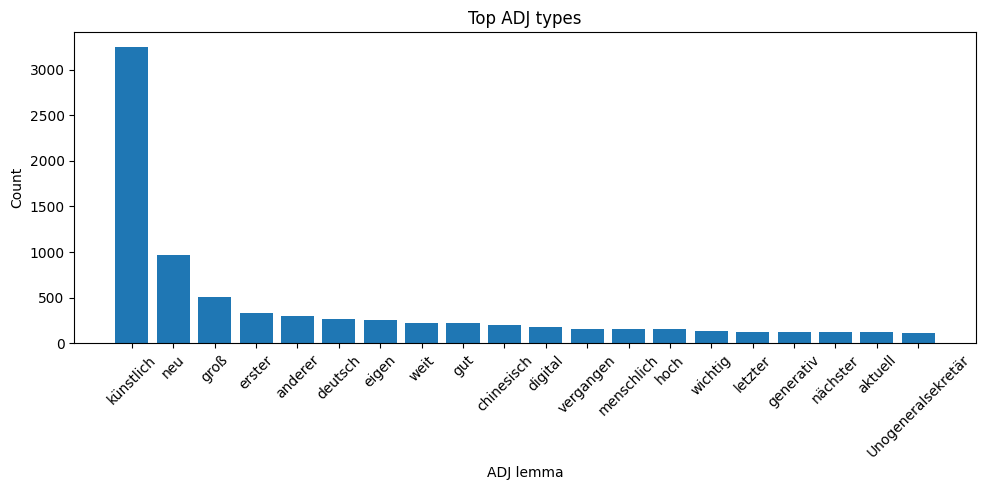

<Figure size 640x480 with 0 Axes>

In [35]:
# count adjectives in all sentences
count_POS(all_sents_df['text'], nlp, 'ADJ')